# Notebook 3 — Evaluation and Comparison
## PharmaGraph-OTC: Answering Drug-Safety Questions over Over-the-Counter Medicines — GraphRAG vs Vector RAG
**AIML506 · Course Assignment** · Dataset: *Pharma-safe Index Dataset* (Mendeley Data, DOI **10.17632/m78j7ctwhn.2**).

**What this notebook does (Tasks 5-7):** builds a 30+ question benchmark with gold answers computed from the data, runs **GraphRAG** and three **Vector RAG** variants with the *same generator and prompt*,
computes retrieval / answer / grounding / efficiency metrics overall and **by question type**, validates an LLM judge against hand labels, runs a **model ablation**, a **Text2Cypher** check, a cost comparison and an error analysis.

**Inputs (add as Kaggle inputs):** output of Notebook 1 (`graph_rag.py`, `ps_vocab.py`, `rag_common.py`, `drug_records.json`, `build_costs_graph.json`) and Notebook 2 (`vector_rag.py`, `rag_common.py`, `build_costs_vector.json`).
**Secrets:** `NEO4J_URI`, `NEO4J_USERNAME`, `NEO4J_PASSWORD`. Internet on, GPU on (two T4s recommended: the judge model is larger than the generators).
**Outputs:** `benchmark.csv`, `results_per_question.csv`, `table_overall.csv`, `table_by_type.csv`, `table_ablation.csv`, `table_cost.csv`, `judge_validation_sample.csv`, `error_cases.csv`.

In [1]:
!pip -q install neo4j rapidfuzz chromadb sentence-transformers rank_bm25 bert-score 2>&1 | tail -1
import os, re, sys, json, time, glob, random, shutil, hashlib, warnings
from collections import Counter, defaultdict
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch
warnings.filterwarnings("ignore")
pd.set_option("display.width", 220); pd.set_option("display.max_colwidth", 120)

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
OUT = "/kaggle/working"; os.makedirs(OUT, exist_ok=True); os.chdir(OUT); os.makedirs(f"{OUT}/figures", exist_ok=True)

# ---------------- configuration ----------------
GEN_MODELS    = ["qwen2.5:7b-instruct", "qwen2.5:3b-instruct"]   # first = MAIN comparison; second = model ablation (size)
MAIN          = GEN_MODELS[0]
JUDGE_MODEL   = "qwen2.5:14b-instruct"       # different from, and larger than, the generators
K_EVAL, K_CONTEXT = 5, 10                    # metrics @5; up to 10 evidence items offered to the generator
EMB_MODEL     = "BAAI/bge-small-en-v1.5"
ABLATION_SYSTEMS = ["GraphRAG", "VectorRAG-dense"]   # systems re-run with the ablation model(s)
RUN_JUDGE, RUN_BERTSCORE, RUN_T2C = True, True, True

google-adk 2.7.1 requires opentelemetry-sdk<=1.42.1,>=1.39, but you have opentelemetry-sdk 1.45.2 which is incompatible.


In [2]:
# ---- locate the artefacts of notebooks 1 and 2, check that the shared module is identical ----------------------------------------------------------------------------
def find_one(name):
    hits = sorted(glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"{OUT}/{name}"))
    assert hits, f"{name} not found - add the outputs of notebooks 1 and 2 as inputs."
    return hits[0]
for name in ("graph_rag.py", "vector_rag.py", "ps_vocab.py", "drug_records.json"):
    d = os.path.dirname(find_one(name)); sys.path.insert(0, d); print(f"{name:20s} <- {d}")
copies = glob.glob("/kaggle/input/**/rag_common.py", recursive=True) + glob.glob(f"{OUT}/rag_common.py")
md5s = {hashlib.md5(open(p, "rb").read()).hexdigest() for p in copies}
print("rag_common.py copies found:", len(copies), "| distinct versions:", len(md5s))
assert len(md5s) == 1, "rag_common.py differs between notebooks - the comparison would NOT be fair. Re-run notebooks 1 and 2 with the same module."
import rag_common as rc, graph_rag as gr, vector_rag as vr
recs = rc.load_records(find_one("drug_records.json"))
sp = glob.glob("/kaggle/input/**/schema_note.txt", recursive=True)
if sp: rc.set_schema_note(open(sp[0]).read())
print(len(recs), "drug records | prompt hash:", hashlib.md5(rc.SYSTEM_PROMPT.encode()).hexdigest()[:8])

graph_rag.py         <- /kaggle/input/notebooks/sababahoquesaba/notebook-1-data-preparation-and-graphrag-neo4j
vector_rag.py        <- /kaggle/input/notebooks/sababahoquesaba/notebook-2-vector-rag
ps_vocab.py          <- /kaggle/input/notebooks/sababahoquesaba/notebook-1-data-preparation-and-graphrag-neo4j
drug_records.json    <- /kaggle/input/notebooks/sababahoquesaba/notebook-1-data-preparation-and-graphrag-neo4j
rag_common.py copies found: 2 | distinct versions: 1
112 drug records | prompt hash: fd3e2ebd


In [3]:
# ---- connect to Aura (Kaggle Secrets) and check the graph matches the records ------------------------------------------------------------------------------------------------
from neo4j import GraphDatabase
try:
    from kaggle_secrets import UserSecretsClient
    _s = UserSecretsClient(); get_secret = lambda k: _s.get_secret(k)
except Exception:
    get_secret = lambda k: os.environ[k]
driver = GraphDatabase.driver(get_secret("NEO4J_URI"), auth=(get_secret("NEO4J_USERNAME"), get_secret("NEO4J_PASSWORD")))
driver.verify_connectivity()
def run_cypher(cy, **params):
    with driver.session() as s: return s.execute_read(lambda tx: tx.run(cy, **params).data())
n_graph = run_cypher("MATCH (d:Drug) RETURN count(d) AS n")[0]["n"]
print("drugs in graph:", n_graph, "| drug records:", len(recs)); assert n_graph == len(recs), "Graph and records differ - re-run notebook 1."
idx = gr.EntityIndex(driver, None); print("entity index:", idx.load())
G = gr.GraphRetriever(driver, None, idx)

drugs in graph: 112 | drug records: 112
entity index: {'drug': 107, 'ingredient': 185, 'category': 6, 'unit': 29}


In [4]:
# ---- vector retrievers (index rebuilt here: ~1 minute, deterministic, identical to notebook 2) -----------------------------------------------------------------------------------
from sentence_transformers import SentenceTransformer
import chromadb
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
embedder = SentenceTransformer(EMB_MODEL, device=DEVICE)
PERSIST = f"{OUT}/chroma_eval"; shutil.rmtree(PERSIST, ignore_errors=True)
cl = chromadb.PersistentClient(path=PERSIST)
ids, docs, metas = vr.build_record_docs(recs); vr.build_collection(cl, "drug_record", ids, docs, metas, embedder)
ids, docs, metas = vr.build_fact_docs(recs);   vr.build_collection(cl, "drug_fact", ids, docs, metas, embedder)
Vrec, Vfact = vr.VectorRetriever(PERSIST, "drug_record", embedder), vr.VectorRetriever(PERSIST, "drug_fact", embedder)
SYSTEMS = {"GraphRAG": lambda q: G.retrieve(q, k=K_CONTEXT, mode="template"),
           "VectorRAG-dense": lambda q: Vrec.retrieve(q, k=K_CONTEXT, mode="dense"),
           "VectorRAG-hybrid": lambda q: Vrec.retrieve(q, k=K_CONTEXT, mode="hybrid"),
           "VectorRAG-fact": lambda q: Vfact.retrieve(q, k=K_CONTEXT, mode="dense")}
print(list(SYSTEMS))

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/94.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/52.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/743 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  133MB            

... (4 outputs left out)

tokenizer.json:   0%|          | 0.00/711k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/125 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

['GraphRAG', 'VectorRAG-dense', 'VectorRAG-hybrid', 'VectorRAG-fact']


In [5]:
# ---- Ollama: start the server and pull the generators and the judge ----------------------------------------------------------------------------------------------------------------------
if shutil.which("ollama") is None:
    !apt-get -qq install -y zstd > /dev/null 2>&1
    !curl -fsSL https://ollama.com/install.sh | sh > /dev/null 2>&1
rc.ensure_ollama()
for m in GEN_MODELS + ([JUDGE_MODEL] if RUN_JUDGE else []):
    t0 = time.perf_counter(); rc.pull(m); print(f"{m}: ready ({time.perf_counter() - t0:.0f} s)")

pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest 
pulling 2bada8a74506:   1% ▕                  ▏  45 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   3% ▕                  ▏ 129 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   4% ▕                  ▏ 169 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   6% ▕                  ▏ 258 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   7% ▕█                 ▏ 343 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:   8% ▕█                 ▏ 382 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  10% ▕█                 ▏ 470 MB/4.7 GB                  pulling manifest 
pulling 2bada8a74506:  12% ▕██                ▏ 560 MB/4

qwen2.5:7b-instruct: ready (38 s)


pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest ⠏ pulling manifest ⠋ pulling manifest ⠙ pulling manifest 
pulling 5ee4f07cdb9b:   0% ▕                  ▏ 6.4 MB/1.9 GB                  pulling manifest 
pulling 5ee4f07cdb9b:   5% ▕                  ▏  96 MB/1.9 GB                  pulling manifest 
pulling 5ee4f07cdb9b:   7% ▕█                 ▏ 142 MB/1.9 GB                  pulling manifest 
pulling 5ee4f07cdb9b:  12% ▕██                ▏ 225 MB/1.9 GB                  pulling manifest 
pulling 5ee4f07cdb9b:  16% ▕██                ▏ 315 MB/1.9 GB                  pulling manifest 
pulling 5ee4f07cdb9b:  19% ▕███               ▏ 359 MB/1.9 GB                  pulling manifest 
pulling 5ee4f07cdb9b:  24% ▕████              ▏ 454 MB/1.9 GB                  pulling manifest 
pulling 5ee4f07cdb9b:  29% ▕█████             ▏ 556 MB/1.9 GB              

qwen2.5:3b-instruct: ready (16 s)


pulling manifest ⠋ pulling manifest ⠙ pulling manifest ⠹ pulling manifest ⠸ pulling manifest ⠼ pulling manifest ⠴ pulling manifest ⠦ pulling manifest ⠧ pulling manifest ⠇ pulling manifest 
pulling 2049f5674b1e:   0% ▕                  ▏ 1.6 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   0% ▕                  ▏  36 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   1% ▕                  ▏ 127 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   2% ▕                  ▏ 205 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   3% ▕                  ▏ 247 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   4% ▕                  ▏ 338 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   5% ▕                  ▏ 427 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   5% ▕                  ▏ 474 MB/9.0 GB                  pulling manifest 
pulling 2049f5674b1e:   6% ▕█      

qwen2.5:14b-instruct: ready (68 s)


pulling manifest 
pulling 2049f5674b1e: 100% ▕█████████████████ ▏ 9.0 GB/9.0 GB   55 MB/s      0s
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 832dd9e00a68: 100% ▕██████████████████▏  11 KB                         
pulling db59b814cab7: 100% ▕██████████████████▏  488 B                         
verifying sha256 digest ⠧ pulling manifest 
pulling 2049f5674b1e: 100% ▕█████████████████ ▏ 9.0 GB/9.0 GB   55 MB/s      0s
pulling 66b9ea09bd5b: 100% ▕██████████████████▏   68 B                         
pulling eb4402837c78: 100% ▕██████████████████▏ 1.5 KB                         
pulling 832dd9e00a68: 100% ▕██████████████████▏  11 KB                         
pulling db59b814cab7: 100% ▕██████████████████▏  488 B                         
verifying sha256 digest 
writing manifest 
success 


## Task 6 — Benchmark
The benchmark is **generated from the data** (pandas), so every gold answer is verifiable; the code is below (`ps_bench.py`) and the questions are saved to `benchmark.csv` (include it in the appendix).

| Type | What it needs | Example |
|---|---|---|
| single-hop | one fact about one drug | *Which disease category does 'X' belong to?* · *What is the price of 'X' per strip?* |
| multi-hop | two or more linked facts | *Which other drugs share an ingredient with 'X'?* · *Which drugs in the 'cough' category list drowsiness as a side effect?* |
| aggregation | counting, ranking, intersecting sets | *How many drugs contain Y?* · *Which 3 categories have the most drugs?* |
| semantic / descriptive | free-text description | *Describe the drug 'X'…* · *What precautions apply to 'X'?* |
| unanswerable | information the data does not hold | *Who manufactures 'X'?* · *What is the mechanism of action of Y?* |

**Gold answers and keys.** Each question has `answer_keys` (items the answer must contain) and `evidence_keys` (items the retrieved evidence must contain). Keys are plain strings or `re:` patterns (used for side-effect / contraindication terms
so that *"nauseous"* counts for *nausea*). Gold for term-based questions is defined by the **same vocabulary** that built the graph; this is validated against hand labels in Notebook 1 and listed as a threat to validity.

In [6]:
%%writefile ps_bench.py
"""Benchmark builder + metric functions for notebook 3 (Pharma-safe Index)."""
import json
import re
from collections import Counter, defaultdict

import numpy as np
import pandas as pd

import ps_vocab as V

REFUSAL_GOLD = "The available data does not contain this information."


# ============================================================================ text matching
def norm_text(s):
    s = re.sub(r"(?<=\d)[.,](?=\d{3}(?!\d))", "", str(s))      # 2,000 / 2.000 -> 2000
    s = re.sub(r"[^a-z0-9]+", " ", s.lower())
    s = re.sub(r"(\d)([a-z])", r"\1 \2", s)                    # 500mg -> 500 mg
    return re.sub(r"\s+", " ", s).strip()


def contains_key(text, key):
    """key = plain string (word-boundary match) or 're:<pattern>' (vocabulary pattern, so 'nauseous' counts for nausea)."""
    key = str(key)
    nt = norm_text(text)
    if key.startswith("re:"):
        return re.search(key[3:], nt, re.I) is not None
    nk = norm_text(key)
    if not nk:
        return False
    return re.search(r"(?<![a-z0-9])" + re.escape(nk) + r"(?![a-z0-9])", nt) is not None


def split_keys(s):
    if isinstance(s, list):
        return s
    try:
        v = json.loads(s)
        return v if isinstance(v, list) else []
    except Exception:
        return []



# ============================================================================ benchmark builder
def build_benchmark(recs, seed=42, n_per_type=None):
    """Questions + gold answers (computed from the records) + gold Cypher. Raises nothing: types that cannot be filled are reported."""
    rng = np.random.default_rng(seed)
    N = {"single": 7, "multi": 7, "agg": 7, "sem": 6, "unans": 7}
    N.update(n_per_type or {})
    name = {r["id"]: r["name"] for r in recs}
    nkey = {r["id"]: r["name_key"] for r in recs}
    cat = {r["id"]: r["category"] for r in recs}
    ckey = {r["id"]: r["category_key"] for r in recs}
    ing = {r["id"]: set(r["ingredient_keys"]) for r in recs}
    ing_name = {k: n for r in recs for k, n in zip(r["ingredient_keys"], r["ingredient_names"])}
    eff = {r["id"]: set(r.get("effect_terms", [])) for r in recs}
    con = {r["id"]: set(r.get("contra_terms", [])) for r in recs}
    iint = {r["id"]: set(r.get("interaction_ingredients", [])) for r in recs}
    prices = defaultdict(lambda: defaultdict(list))
    for r in recs:
        for u, p in r["prices"]:
            prices[r["id"]][u.lower()].append(int(p))
    ids = [r["id"] for r in recs]
    cat_name = {ckey[i]: cat[i] for i in ids}
    qs = []

    def rk(term, kind):                                       # regex key for a vocabulary term
        return "re:" + (V.SIDE_EFFECT_VOCAB if kind == "effect" else V.CONTRA_VOCAB)[term]

    def add(qtype, question, answer, keys, ev=None, ents=(), cypher="", params=None):
        qs.append({"qtype": qtype, "question": question, "gold_answer": answer, "answer_keys": json.dumps(list(keys)),
                   "evidence_keys": json.dumps(list(keys if ev is None else ev)), "gold_entities": ";".join(ents),
                   "gold_cypher": cypher, "cypher_params": json.dumps(params or {})})

    def shuffled(xs):
        xs = list(xs)
        return [xs[i] for i in rng.permutation(len(xs))]

    def drugs_where(pred):
        return sorted(name[i] for i in ids if pred(i))

    # ------------------------------------------------------------------ single-hop
    n_cat, n_price, n_ing = max(1, round(N["single"] * 2 / 7)), max(1, round(N["single"] * 2 / 7)), max(1, round(N["single"] * 2 / 7))
    n_per = max(0, N["single"] - n_cat - n_price - n_ing)
    for i in shuffled(ids)[:n_cat]:
        add("single_hop", f"Which disease category does '{name[i]}' belong to?", f"'{name[i]}' belongs to the category '{cat[i]}'.", [cat[i]],
            ents=[f"drug:{nkey[i]}"], cypher="MATCH (:Drug {name_key:$dkey})-[:IN_CATEGORY]->(c:Category) RETURN c.name AS category", params={"dkey": nkey[i]})
    cand = [(i, u, ps[0]) for i in ids for u, ps in prices[i].items() if len(ps) == 1]
    for i, u, p in shuffled(cand)[:n_price]:
        add("single_hop", f"What is the price of '{name[i]}' per {u}?", f"'{name[i]}' costs IDR {p} per {u}.", [str(p)],
            ents=[f"drug:{nkey[i]}", f"unit:{u}"],
            cypher="MATCH (:Drug {name_key:$dkey})-[s:SOLD_AS]->(:Unit {key:$ukey}) RETURN s.price AS price", params={"dkey": nkey[i], "ukey": u})
    for i in shuffled([i for i in ids if 1 <= len(ing[i]) <= 3])[:n_ing]:
        names = [ing_name[k] for k in sorted(ing[i])]
        add("single_hop", f"Which active ingredients does '{name[i]}' contain?", f"'{name[i]}' contains {', '.join(names)}.", names,
            ents=[f"drug:{nkey[i]}"], cypher="MATCH (:Drug {name_key:$dkey})-[:CONTAINS]->(i:Ingredient) RETURN i.name AS ingredient", params={"dkey": nkey[i]})
    rx = re.compile(r"(\d+)\s*(days?|weeks?|months?|hari|minggu|bulan)", re.I)
    for i in shuffled(ids):
        if n_per <= 0:
            break
        per = next((r["usage_period"] for r in recs if r["id"] == i), "")
        m = rx.search(per or "")
        if m:
            key = f"{m.group(1)} {m.group(2)}"
            add("single_hop", f"For how long may '{name[i]}' be used?", f"'{name[i]}': {per}", [key], ents=[f"drug:{nkey[i]}"],
                cypher="MATCH (d:Drug {name_key:$dkey}) RETURN d.usage_period AS period", params={"dkey": nkey[i]})
            n_per -= 1
    while sum(q["qtype"] == "single_hop" for q in qs) < N["single"]:       # top up with categories if some sub-type is scarce
        i = shuffled(ids)[0]
        if any(i_q["question"].endswith(f"'{name[i]}' belong to?") for i_q in qs):
            continue
        add("single_hop", f"Which disease category does '{name[i]}' belong to?", f"'{name[i]}' belongs to the category '{cat[i]}'.", [cat[i]],
            ents=[f"drug:{nkey[i]}"], cypher="MATCH (:Drug {name_key:$dkey})-[:IN_CATEGORY]->(c:Category) RETURN c.name AS category", params={"dkey": nkey[i]})

    # ------------------------------------------------------------------ multi-hop
    n_a = max(1, round(N["multi"] * 2 / 7)); n_b = max(1, round(N["multi"] * 2 / 7))
    n_c = max(1, round(N["multi"] / 7)); n_d = max(1, round(N["multi"] / 7)); n_e = max(0, N["multi"] - n_a - n_b - n_c - n_d)
    for hi in (8, 14):
        done = sum(1 for q in qs if q["question"].startswith("Which other drugs share"))
        for i in shuffled(ids):
            if done >= n_a:
                break
            others = drugs_where(lambda j: j != i and ing[j] & ing[i])
            if 2 <= len(others) <= hi and not any(q["question"] == f"Which other drugs share at least one active ingredient with '{name[i]}'?" for q in qs):
                add("multi_hop", f"Which other drugs share at least one active ingredient with '{name[i]}'?", "Drugs: " + ", ".join(others) + ".", others,
                    ents=[f"drug:{nkey[i]}"],
                    cypher=("MATCH (:Drug {name_key:$dkey})-[:CONTAINS]->(:Ingredient)<-[:CONTAINS]-(o:Drug) WHERE o.name_key <> $dkey "
                            "RETURN DISTINCT o.name AS name"), params={"dkey": nkey[i]})
                done += 1

    def pair_questions(n, kind, label):
        pool = [(ckey[i], t) for i in ids for t in (eff[i] if kind == "effect" else con[i])]
        pairs = [(c, t) for (c, t), cnt in Counter(pool).items() if 2 <= cnt <= 8]
        for c, t in shuffled(pairs)[:n]:
            names = drugs_where(lambda j: ckey[j] == c and t in (eff[j] if kind == "effect" else con[j]))
            if kind == "effect":
                q = f"Which drugs in the '{cat_name[c]}' category list {t} as a side effect?"
                cy = ("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey}) RETURN DISTINCT d.name AS name")
                pr = {"ckey": c, "ekey": t}
            else:
                q = f"Which drugs in the '{cat_name[c]}' category list {t} as a contraindication?"
                cy = ("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:CONTRAINDICATED_IN]->(:ContraTerm {key:$kkey}) RETURN DISTINCT d.name AS name")
                pr = {"ckey": c, "kkey": t}
            add("multi_hop", q, "Drugs: " + ", ".join(names) + ".", names, ents=[f"category:{c}", f"{label}:{t}"], cypher=cy, params=pr)
    pair_questions(n_b, "effect", "effect")
    pair_questions(n_c, "contra", "contra")
    icount = Counter(k for i in ids for k in iint[i])
    for k in shuffled([k for k, c in icount.items() if 2 <= c <= 8])[:n_d]:
        names = drugs_where(lambda j: k in iint[j])
        add("multi_hop", f"Which drugs have a documented interaction statement that mentions {ing_name[k]}?", "Drugs: " + ", ".join(names) + ".", names,
            ents=[f"ingredient:{k}"],
            cypher=("MATCH (:Ingredient {key:$ikey})<-[:INVOLVES]-(:Interaction)<-[:HAS_INTERACTION]-(d:Drug) RETURN DISTINCT d.name AS name"), params={"ikey": k})
    pool = Counter((ckey[i], k) for i in ids for k in ing[i])
    for (c, k) in shuffled([p for p, cnt in pool.items() if 2 <= cnt <= 8])[:n_e]:
        names = drugs_where(lambda j: ckey[j] == c and k in ing[j])
        add("multi_hop", f"Which drugs in the '{cat_name[c]}' category contain {ing_name[k]}?", "Drugs: " + ", ".join(names) + ".", names,
            ents=[f"category:{c}", f"ingredient:{k}"],
            cypher=("MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug)-[:CONTAINS]->(:Ingredient {key:$ikey}) RETURN DISTINCT d.name AS name"),
            params={"ckey": c, "ikey": k})

    # ------------------------------------------------------------------ aggregation
    ccount = Counter(ckey[i] for i in ids)
    for c in shuffled([c for c, n in ccount.items() if n >= 3])[:1]:
        add("aggregation", f"How many drugs belong to the '{cat_name[c]}' category?", f"{ccount[c]} drugs belong to the '{cat_name[c]}' category.", [str(ccount[c])],
            ents=[f"category:{c}"], cypher="MATCH (:Category {key:$ckey})<-[:IN_CATEGORY]-(d:Drug) RETURN count(DISTINCT d) AS n", params={"ckey": c})
    ecount = Counter(t for i in ids for t in eff[i])
    for t in shuffled([t for t, n in ecount.items() if 3 <= n <= 60])[:1]:
        add("aggregation", f"How many drugs list {t} as a side effect?", f"{ecount[t]} drugs list {t} as a side effect.", [str(ecount[t])],
            ents=[f"effect:{t}"], cypher="MATCH (:SideEffectTerm {key:$ekey})<-[:MAY_CAUSE]-(d:Drug) RETURN count(DISTINCT d) AS n", params={"ekey": t})
    icount_all = Counter(k for i in ids for k in ing[i])
    for k in shuffled([k for k, n in icount_all.items() if 3 <= n <= 60])[:1]:
        add("aggregation", f"How many drugs contain {ing_name[k]}?", f"{icount_all[k]} drugs contain {ing_name[k]}.", [str(icount_all[k])],
            ents=[f"ingredient:{k}"], cypher="MATCH (:Ingredient {key:$ikey})<-[:CONTAINS]-(d:Drug) RETURN count(DISTINCT d) AS n", params={"ikey": k})

    def top3(counter, label_of):
        items = sorted(counter.items(), key=lambda x: (-x[1], label_of(x[0])))
        return items[:3] if len(items) > 3 and items[2][1] > items[3][1] else None
    t = top3(icount_all, lambda k: ing_name[k])
    if t:
        names = [ing_name[k] for k, _ in t]
        add("aggregation", "Which 3 active ingredients are used in the most drugs?", "Top 3: " + ", ".join(names) + ".", names,
            cypher=("MATCH (i:Ingredient)<-[:CONTAINS]-(d:Drug) WITH i, count(DISTINCT d) AS n ORDER BY n DESC, i.name RETURN i.name AS name, n LIMIT $top"),
            params={"top": 3})
    t = top3(ccount, lambda c: cat_name[c])
    if t:
        names = [cat_name[c] for c, _ in t]
        add("aggregation", "Which 3 categories have the most drugs?", "Top 3: " + ", ".join(names) + ".", names,
            cypher=("MATCH (c:Category)<-[:IN_CATEGORY]-(d:Drug) WITH c, count(DISTINCT d) AS n ORDER BY n DESC, c.name RETURN c.name AS name, n LIMIT $top"),
            params={"top": 3})
    t = top3(ecount, lambda x: x)
    if t:
        terms = [k for k, _ in t]
        add("aggregation", "Which 3 side effects are listed by the most drugs?", "Top 3: " + ", ".join(terms) + ".", [rk(x, "effect") for x in terms],
            cypher=("MATCH (t:SideEffectTerm)<-[:MAY_CAUSE]-(d:Drug) WITH t, count(DISTINCT d) AS n ORDER BY n DESC, t.name RETURN t.name AS name, n LIMIT $top"),
            params={"top": 3})
    both = [(a, b) for a in ecount for b in ecount if a < b and 2 <= len(drugs_where(lambda j: a in eff[j] and b in eff[j])) <= 8]
    for a, b in shuffled(both)[:max(1, N["agg"] - sum(q["qtype"] == "aggregation" for q in qs))]:
        names = drugs_where(lambda j: a in eff[j] and b in eff[j])
        add("aggregation", f"Which drugs list both {a} and {b} as side effects?", "Drugs: " + ", ".join(names) + ".", names, ents=[f"effect:{a}", f"effect:{b}"],
            cypher=("MATCH (d:Drug)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey}) MATCH (d)-[:MAY_CAUSE]->(:SideEffectTerm {key:$ekey2}) RETURN DISTINCT d.name AS name"),
            params={"ekey": a, "ekey2": b})

    # ------------------------------------------------------------------ semantic / descriptive
    for i in shuffled(ids)[:max(1, N["sem"] // 2)]:
        names = [ing_name[k] for k in sorted(ing[i])][:2]
        add("semantic", f"Describe the drug '{name[i]}': what is it used for and what does it contain?",
            f"'{name[i]}' is a {cat[i]} drug containing {', '.join(names)}.", [cat[i]] + names, ents=[f"drug:{nkey[i]}"])
    for i in shuffled([i for i in ids if con[i]])[:max(1, N["sem"] // 3)]:
        terms = sorted(con[i])[:2]
        add("semantic", f"What precautions apply to '{name[i]}'?", f"'{name[i]}' is contraindicated in: {', '.join(terms)}.", [rk(x, "contra") for x in terms],
            ents=[f"drug:{nkey[i]}"])
    for c in shuffled([c for c, n in ccount.items() if n >= 6]):
        if sum(q["qtype"] == "semantic" for q in qs) >= N["sem"]:
            break
        cnt = Counter(k for i in ids if ckey[i] == c for k in ing[i])
        t = top3(cnt, lambda k: ing_name[k])
        if t:
            names = [ing_name[k] for k, _ in t[:2]]
            add("semantic", f"Give a short overview of the '{cat_name[c]}' drugs: what are the most common ingredients?", f"Most common ingredients: {', '.join(names)}.",
                names, ents=[f"category:{c}"])

    # ------------------------------------------------------------------ unanswerable
    alltext = " ".join(norm_text(rc_text) for r in recs for rc_text in [json.dumps(r)])
    absent = [x for x in ["amoxicillin", "ciprofloxacin", "metformin", "atorvastatin", "omeprazole", "warfarin", "insulin", "diazepam"] if x not in alltext]
    pick = shuffled(ids)
    ing_pick = shuffled(sorted(ing_name))
    un = [f"Who manufactures '{name[pick[0]]}'?",
          f"What is the mechanism of action of {ing_name[ing_pick[0]]}?",
          f"What are the storage conditions for '{name[pick[1]]}'?",
          f"Is '{name[pick[2]]}' approved by the Indonesian food and drug authority (BPOM)?",
          f"What is the adult dose of {absent[0] if absent else 'warfarin'}?",
          f"Which pharmacy sells '{name[pick[3]]}' at the lowest price?",
          "What is the price of the drug 'Zorvexa Plus 9' per strip?"]
    for q in un[:N["unans"]]:
        add("unanswerable", q, REFUSAL_GOLD, [], ev=[])
    out = pd.DataFrame(qs)
    out.insert(0, "qid", [f"Q{i + 1:02d}" for i in range(len(out))])
    return out

# ============================================================================ metrics
def retrieval_metrics(items, ev_keys, k=5):
    """Relevance is defined at item level: an item is relevant when it contains >= 1 evidence key."""
    if not ev_keys:
        return {}
    top = items[:k]
    rel = [any(contains_key(it["text"], key) for key in ev_keys) for it in top]
    blob = " ".join(it["text"] for it in top)
    blob10 = " ".join(it["text"] for it in items[:10])
    first = next((i + 1 for i, r in enumerate(rel) if r), None)
    dcg = sum(1.0 / np.log2(i + 2) for i, r in enumerate(rel) if r)
    idcg = sum(1.0 / np.log2(i + 2) for i in range(min(k, len(ev_keys))))
    return {"hit_at_k": float(any(rel)), "precision_at_k": sum(rel) / max(1, len(top)),
            "recall_at_k": float(np.mean([contains_key(blob, key) for key in ev_keys])),
            "recall_at_10": float(np.mean([contains_key(blob10, key) for key in ev_keys])),
            "mrr": 1.0 / first if first else 0.0, "ndcg_at_k": min(1.0, dcg / idcg) if idcg else 0.0}


def _tok(s):
    s = re.sub(r"\b(a|an|the)\b", " ", norm_text(s))
    return s.split()


def token_f1(pred, gold):
    p, g = _tok(pred), _tok(gold)
    common = Counter(p) & Counter(g)
    ns = sum(common.values())
    if not p or not g or ns == 0:
        return 0.0
    pr, rc_ = ns / len(p), ns / len(g)
    return 2 * pr * rc_ / (pr + rc_)


def key_accuracy(answer, keys):
    return float(bool(keys) and all(contains_key(answer, k) for k in keys))


def citation_validity(cited, kept_ids, answerable_pred):
    if not answerable_pred:
        return np.nan
    if not cited:
        return 0.0
    return float(np.mean([c in set(kept_ids) for c in cited]))


def link_scores(pred_links, gold_entities):
    gold = {tuple(e.split(":", 1)) for e in gold_entities.split(";") if e}
    if not gold:
        return {}
    pred = {(l["type"], l["key"]) for l in (pred_links or [])}
    def prf(p, g):
        tp = len(p & g)
        pr = tp / len(p) if p else 0.0
        rc_ = tp / len(g) if g else 0.0
        return pr, rc_, (2 * pr * rc_ / (pr + rc_) if pr + rc_ else 0.0)
    s = prf(pred, gold)
    l = prf({k for _, k in pred}, {k for _, k in gold})
    return {"link_p": s[0], "link_r": s[1], "link_f1": s[2], "link_f1_lenient": l[2]}


def bootstrap_ci(values, n=2000, seed=0):
    v = np.asarray([x for x in values if not pd.isna(x)], dtype=float)
    if len(v) == 0:
        return (np.nan, np.nan)
    rng = np.random.default_rng(seed)
    means = [rng.choice(v, len(v)).mean() for _ in range(n)]
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))


def flatten_values(rows):
    """Set of normalised scalar values in a Cypher result (for execution-accuracy checks)."""
    out = set()
    for r in rows:
        for v in r.values():
            if isinstance(v, (list, tuple)):
                out.update(norm_text(x) for x in v)
            elif v is not None:
                out.add(norm_text(v))
    return out


def raw_values(rows):
    """All scalar values of a Cypher result as strings (to test whether gold keys occur in them)."""
    out = []
    for r in rows:
        for v in r.values():
            out += [str(x) for x in v] if isinstance(v, (list, tuple)) else ([str(v)] if v is not None else [])
    return out

Writing ps_bench.py


In [7]:
# ---- build and save the benchmark --------------------------------------------------------------------------------------------------------------------------------------------------------------
import ps_bench as B
bench = B.build_benchmark(recs, seed=SEED)
bench.to_csv(f"{OUT}/benchmark.csv", index=False)
counts = bench.qtype.value_counts()
print(len(bench), "questions\n", counts.to_string())
assert len(bench) >= 30 and (counts >= 4).all() and counts.shape[0] == 5, "Benchmark must have >= 30 questions and >= 4 of each of the 5 types."
bench[["qid", "qtype", "question", "answer_keys"]]

34 questions
 qtype
single_hop      7
multi_hop       7
aggregation     7
unanswerable    7
semantic        6


,qid,qtype,question,answer_keys
0,Q01,single_hop,Which disease category does 'Decolgen Tablet' belong to?,"[""flu""]"
1,Q02,single_hop,Which disease category does 'Antasida Doen Tablet Kunyah' belong to?,"[""stomach""]"
2,Q03,single_hop,What is the price of 'Polycrol Forte' per all?,"[""32500""]"
3,Q04,single_hop,What is the price of 'Siladex Cough Cold' per cair 30 ml?,"[""9500""]"
4,Q05,single_hop,Which active ingredients does 'Rhinos Junior' contain?,"[""Chlorphenamine Maleate"", ""Pseudoephedrine HCl""]"
5,Q06,single_hop,Which active ingredients does 'Decolgen Tablet' contain?,"[""Chlorphenamine Maleate"", ""Paracetamol"", ""Phenylpropanolamine HCI""]"
6,Q07,single_hop,For how long may 'Antasida Doen Tablet Kunyah' be used?,"[""2 weeks""]"
7,Q08,multi_hop,Which other drugs share at least one active ingredient with 'Vicks Formula 44'?,"[""Polysilane Cair"", ""Sanadryl DMP"", ""Sanaflu + Batuk"", ""Sanaflu + Batuk"", ""Siladex Cough Cold"", ""Tuzalos"", ""Vicks Fo..."
8,Q09,multi_hop,Which other drugs share at least one active ingredient with 'Komix Herbal Tube'?,"[""Komix Herbal Kids Tube"", ""Komix Herbal Sachet""]"
9,Q10,multi_hop,Which drugs in the 'cough and flu' category list nausea as a side effect?,"[""Bronchitin Expectorant"", ""Nellco Special"", ""Nellco Special"", ""Panadol Cold Flu""]"


In [8]:
# ---- gold-consistency check: do the gold Cypher queries on the LIVE graph reproduce the pandas gold answers? ---------------------------------------------------------------------------------------
rows = []
for r in bench[bench.gold_cypher != ""].itertuples():
    vals = B.raw_values(run_cypher(r.gold_cypher, **json.loads(r.cypher_params)))
    keys = B.split_keys(r.answer_keys)
    ok = bool(keys) and all(any(B.contains_key(v, k) for v in vals) for k in keys)
    rows.append({"qid": r.qid, "qtype": r.qtype, "ok": ok, "n_values": len(vals), "question": r.question[:80]})
gc = pd.DataFrame(rows)
print(f"gold Cypher reproduces the pandas gold: {gc.ok.sum()}/{len(gc)}")
gc[~gc.ok]

gold Cypher reproduces the pandas gold: 21/21


,qid,qtype,ok,n_values,question


## Task 7.1 — Fairness table
| | GraphRAG | Vector RAG (dense / hybrid / fact) |
|---|---|---|
| **Data** | same 112 drug records (nine CSV tables) | same |
| **Generator + prompt** | same model, same system prompt, same JSON answer schema (`rag_common.py`, hash checked above) | same |
| **Generation parameters** | temperature 0, seed 42, `num_ctx` 8192, `num_predict` 400 | same |
| **Context budget** | up to 10 evidence items, ≤ 8,000 characters | same |
| **Evidence unit** | graph fact (one result row, quotes the source sentence) | record or fact chunk |
| **Retrieval** | entity linking → Cypher template | embedding (bge-small, cosine) top-k; hybrid adds BM25 + RRF |
| **What differs** | **only retrieval** | |

In [9]:
# ---- run every system on every question (resumable) -------------------------------------------------------------------------------------------------------------------------------------------
RAW = f"{OUT}/raw_results.jsonl"
done = set()
if os.path.exists(RAW):
    for line in open(RAW): d = json.loads(line); done.add((d["model"], d["system"], d["qid"]))
RET = {}                                                  # retrieval is independent of the generator -> cache per (system, qid)
def retrieve_cached(system, qid, question):
    if (system, qid) not in RET: RET[(system, qid)] = SYSTEMS[system](question)
    return RET[(system, qid)]

t_start = time.perf_counter()
with open(RAW, "a") as f:
    for model in GEN_MODELS:
        systems = list(SYSTEMS) if model == MAIN else ABLATION_SYSTEMS
        for system in systems:
            for r in bench.itertuples():
                if (model, system, r.qid) in done: continue
                ret = retrieve_cached(system, r.qid, r.question)
                ans = rc.generate_answer(model, r.question, ret["items"])
                rec_ = {"model": model, "system": system, "qid": r.qid,
                        "items": [{"id": i["id"], "text": i["text"], "row_ids": i["row_ids"]} for i in ret["items"]],
                        "links": [{"type": l["type"], "key": l["key"]} for l in ret.get("links", [])], "intents": ret.get("intents"),
                        "retrieval_latency_s": ret["retrieval_latency_s"], **{k: ans[k] for k in ("answerable", "answer", "citations", "kept_ids", "gen_latency_s", "prompt_tokens", "output_tokens", "prompt_chars", "parse_ok")}}
                f.write(json.dumps(rec_) + "\n"); f.flush()
            print(f"{model} | {system}: done ({time.perf_counter() - t_start:.0f} s elapsed)")
raw = pd.DataFrame([json.loads(l) for l in open(RAW)])
print(raw.groupby(["model", "system"]).size())

qwen2.5:7b-instruct | GraphRAG: done (211 s elapsed)
qwen2.5:7b-instruct | VectorRAG-dense: done (325 s elapsed)
qwen2.5:7b-instruct | VectorRAG-hybrid: done (429 s elapsed)
qwen2.5:7b-instruct | VectorRAG-fact: done (515 s elapsed)
qwen2.5:3b-instruct | GraphRAG: done (548 s elapsed)
qwen2.5:3b-instruct | VectorRAG-dense: done (596 s elapsed)
model                system          
qwen2.5:3b-instruct  GraphRAG            34
                     VectorRAG-dense     34
qwen2.5:7b-instruct  GraphRAG            34
                     VectorRAG-dense     34
                     VectorRAG-fact      34
                     VectorRAG-hybrid    34
dtype: int64


In [10]:
# ---- per-question metrics ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
bq = bench.set_index("qid")
def score(row):
    q = bq.loc[row.qid]; keys, ev = B.split_keys(q.answer_keys), B.split_keys(q.evidence_keys)
    out = {"model": row.model, "system": row.system, "qid": row.qid, "qtype": q.qtype, "question": q.question}
    refused = (not row.answerable) or bool(rc.REFUSAL_RE.search(row.answer))
    if q.qtype == "unanswerable":
        out.update(accuracy=float(refused), refusal_correct=float(refused))
    else:
        out.update(accuracy=0.0 if refused else B.key_accuracy(row.answer, keys), refused_answerable=float(refused),
                   token_f1=B.token_f1(row.answer, q.gold_answer))
        out.update(B.retrieval_metrics(row.items, ev, k=K_EVAL))
    out["citation_validity"] = B.citation_validity(row.citations, row.kept_ids, not refused)
    if row.system == "GraphRAG": out.update(B.link_scores(row.links, q.gold_entities))
    out.update(retrieval_latency_s=row.retrieval_latency_s, gen_latency_s=row.gen_latency_s, prompt_tokens=row.prompt_tokens, prompt_chars=row.prompt_chars,
               answer=row.answer, gold=q.gold_answer, answerable_pred=not refused, n_items=len(row.items))
    return out
res = pd.DataFrame([score(r) for r in raw.itertuples()])
res.to_csv(f"{OUT}/results_per_question.csv", index=False)
res.groupby(["model", "system"]).size().unstack(0)

model,qwen2.5:3b-instruct,qwen2.5:7b-instruct
system,,
GraphRAG,34.0,34.0
VectorRAG-dense,34.0,34.0
VectorRAG-fact,NaN,34.0
VectorRAG-hybrid,NaN,34.0


## Task 7.2-7.3 — Results
Metrics (Table 2 of the assignment): retrieval **Hit@5, Recall@5, Precision@5, MRR, nDCG@5** (+ Recall@10), answer **accuracy** (key-item match: all required items present), **token F1**, **refusal accuracy**, **citation validity**, GraphRAG **entity-linking P/R/F1**,
efficiency (**median latency, context size**). Relevance is defined at item level: an evidence item is relevant when it contains ≥ 1 evidence key. Precision@5 divides by the number of items actually returned (a one-fact aggregate is not penalised for being short).
With 34 questions **one question moves accuracy by ~3 points** — read differences smaller than that, and the confidence intervals, with care.

In [11]:
# ---- overall table (main generator) ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
main = res[res.model == MAIN]
def overall(d):
    ans, un = d[d.qtype != "unanswerable"], d[d.qtype == "unanswerable"]
    return pd.Series({"accuracy (all 34)": d.accuracy.mean(), "accuracy (answerable)": ans.accuracy.mean(), "refusal accuracy": un.refusal_correct.mean(),
        "token F1": ans.token_f1.mean(), "Hit@5": ans.hit_at_k.mean(), "Recall@5": ans.recall_at_k.mean(), "Precision@5": ans.precision_at_k.mean(),
        "MRR": ans.mrr.mean(), "nDCG@5": ans.ndcg_at_k.mean(), "Recall@10": ans.recall_at_10.mean(), "citation validity": d.citation_validity.mean(),
        "link P": d.get("link_p", pd.Series(dtype=float)).mean(), "link R": d.get("link_r", pd.Series(dtype=float)).mean(), "link F1": d.get("link_f1", pd.Series(dtype=float)).mean(),
        "median retrieval ms": d.retrieval_latency_s.median() * 1000, "median generation s": d.gen_latency_s.median(),
        "median prompt tokens": d.prompt_tokens.median(), "median prompt chars": d.prompt_chars.median()})
table_overall = main.groupby("system").apply(overall).T
ci = {s: B.bootstrap_ci(main[main.system == s].accuracy.values) for s in table_overall.columns}
table_overall.loc["accuracy 95% CI (bootstrap)"] = [f"[{ci[s][0]:.2f}, {ci[s][1]:.2f}]" for s in table_overall.columns]
table_overall.to_csv(f"{OUT}/table_overall.csv"); table_overall

system,GraphRAG,VectorRAG-dense,VectorRAG-fact,VectorRAG-hybrid
accuracy (all 34),0.852941,0.441176,0.558824,0.411765
accuracy (answerable),0.814815,0.296296,0.444444,0.259259
refusal accuracy,1.0,1.0,1.0,1.0
token F1,0.470727,0.270609,0.273258,0.319274
Hit@5,1.0,0.925926,0.814815,0.925926
Recall@5,0.936728,0.813272,0.695988,0.779321
Precision@5,0.756173,0.562963,0.348148,0.518519
MRR,0.87037,0.811111,0.646296,0.802469
nDCG@5,0.836373,0.766464,0.617032,0.777216
Recall@10,1.0,0.83179,0.78858,0.820988


accuracy                                                 Recall@10                                                 n questions
system       GraphRAG VectorRAG-dense VectorRAG-fact VectorRAG-hybrid  GraphRAG VectorRAG-dense VectorRAG-fact VectorRAG-hybrid            
qtype                                                                                                                                      
single_hop       1.00            1.00           1.00              1.0       1.0            1.00           1.00             1.00           7
multi_hop        0.71            0.14           0.14              0.0       1.0            0.59           0.61             0.62           7
aggregation      1.00            0.00           0.29              0.0       1.0            0.76           0.57             0.76           7
semantic         0.50            0.00           0.33              0.0       1.0            1.00           1.00             0.92           6
unanswerable     1.00            1.00           1.00              1.0       NaN             NaN            NaN              NaN           7

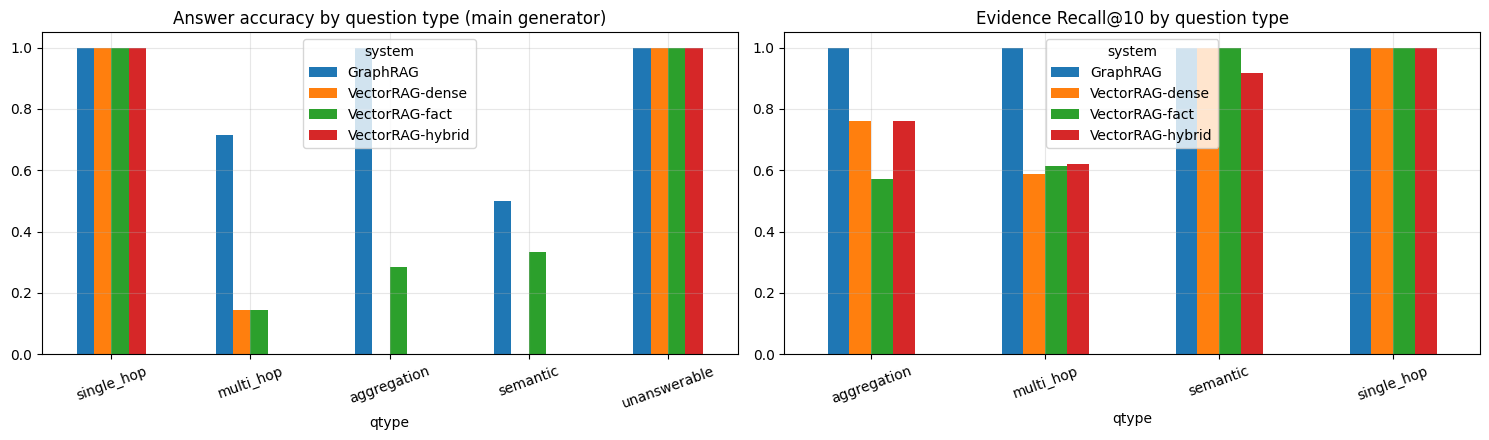

,best system (accuracy),accuracy
qtype,,
single_hop,GraphRAG,1.00
multi_hop,GraphRAG,0.71
aggregation,GraphRAG,1.00
semantic,GraphRAG,0.50
unanswerable,GraphRAG,1.00


In [12]:
# ---- results by question type + charts -----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
by_acc = main.pivot_table(index="qtype", columns="system", values="accuracy", aggfunc="mean").loc[["single_hop", "multi_hop", "aggregation", "semantic", "unanswerable"]]
by_rec = main[main.qtype != "unanswerable"].pivot_table(index="qtype", columns="system", values="recall_at_10", aggfunc="mean")
by_n = main.groupby(["qtype"]).qid.nunique()
table_by_type = pd.concat({"accuracy": by_acc, "Recall@10": by_rec}, axis=1); table_by_type["n questions"] = by_n
table_by_type.to_csv(f"{OUT}/table_by_type.csv"); display(table_by_type.round(2))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.5))
by_acc.plot.bar(ax=axs[0], rot=20, title="Answer accuracy by question type (main generator)"); axs[0].set_ylim(0, 1.05); axs[0].grid(alpha=.3)
by_rec.plot.bar(ax=axs[1], rot=20, title="Evidence Recall@10 by question type"); axs[1].set_ylim(0, 1.05); axs[1].grid(alpha=.3)
plt.tight_layout(); plt.savefig(f"{OUT}/figures/by_type.png", dpi=130); plt.show()
best = by_acc.idxmax(axis=1).rename("best system (accuracy)"); display(pd.concat([best, by_acc.max(axis=1).rename("accuracy")], axis=1).round(2))

## LLM judge and groundedness
**Judge:** `qwen2.5:14b-instruct` (≠ generator, larger). **Rubric (correctness):** *correct* = contains all information of the reference and nothing that contradicts it; *partially_correct* = some but not all required information;
*incorrect* = wrong, missing or contradicting; for unanswerable questions *correct* only if the answer declines. **Faithfulness:** the judge lists the claims of the answer and marks each as supported / not supported by the evidence that was actually in the prompt.
The judge is **validated on hand-labelled answers** (next cells).

In [13]:
# ---- judge: correctness + faithfulness on the main generator's answers --------------------------------------------------------------------------------------------------------------------------------------------------
JUDGE_SYS = """You are a strict grader of question-answering systems. Compare the CANDIDATE answer with the REFERENCE answer.
Return JSON: {"verdict": "correct" | "partially_correct" | "incorrect", "reason": "<one short sentence>"}.
correct = the candidate contains ALL the information of the reference and nothing that contradicts it (extra harmless wording is fine).
partially_correct = some, but not all, required information, or correct information mixed with a wrong item.
incorrect = wrong, missing, or contradicting. If the reference says the data does not contain the information, the candidate is correct only if it clearly declines to answer."""
JUDGE_SCHEMA = {"type": "object", "properties": {"verdict": {"type": "string", "enum": ["correct", "partially_correct", "incorrect"]}, "reason": {"type": "string"}}, "required": ["verdict", "reason"]}
FAITH_SYS = """You check whether an ANSWER is supported by the EVIDENCE. Split the answer into atomic claims and mark each as supported or not supported by the evidence only.
Return JSON: {"claims": [{"claim": "...", "supported": true|false}]}. A refusal such as 'the data does not contain this information' has no claims: return {"claims": []}."""
FAITH_SCHEMA = {"type": "object", "properties": {"claims": {"type": "array", "items": {"type": "object", "properties": {"claim": {"type": "string"}, "supported": {"type": "boolean"}}, "required": ["claim", "supported"]}}}, "required": ["claims"]}
raw_main = raw[raw.model == MAIN].set_index(["system", "qid"])
J = f"{OUT}/judge_results.jsonl"; jdone = {}
if os.path.exists(J):
    for l in open(J): d = json.loads(l); jdone[(d["system"], d["qid"])] = d
if RUN_JUDGE:
    with open(J, "a") as f:
        for r in main.itertuples():
            if (r.system, r.qid) in jdone: continue
            rr = raw_main.loc[(r.system, r.qid)]
            ev = "\n".join(i["text"] for i in rr["items"] if i["id"] in set(rr.kept_ids)) or "(none)"
            v = json.loads(rc.chat(JUDGE_MODEL, JUDGE_SYS, f"QUESTION: {r.question}\nREFERENCE: {r.gold}\nCANDIDATE: {r.answer}", schema=JUDGE_SCHEMA, options={"num_predict": 150})["text"])
            cl = json.loads(rc.chat(JUDGE_MODEL, FAITH_SYS, f"EVIDENCE:\n{ev}\n\nANSWER: {r.answer}", schema=FAITH_SCHEMA, options={"num_predict": 500})["text"]).get("claims", [])
            d = {"system": r.system, "qid": r.qid, "verdict": v["verdict"], "reason": v["reason"], "n_claims": len(cl), "n_supported": sum(bool(c.get("supported")) for c in cl)}
            jdone[(r.system, r.qid)] = d; f.write(json.dumps(d) + "\n"); f.flush()
jd = pd.DataFrame(jdone.values())
if len(jd):
    jd["judge_score"] = jd.verdict.map({"correct": 1.0, "partially_correct": 0.5, "incorrect": 0.0})
    jd["faithfulness"] = np.where(jd.n_claims > 0, jd.n_supported / jd.n_claims.clip(lower=1), np.nan)
    judge_tab = jd.groupby("system").agg(judge_correctness=("judge_score", "mean"), faithfulness=("faithfulness", "mean"), n_with_claims=("faithfulness", "count"))
    display(judge_tab.round(3))
    jt = jd.merge(bq[["qtype"]], left_on="qid", right_index=True).pivot_table(index="qtype", columns="system", values="judge_score", aggfunc="mean"); display(jt.round(2))
    table_overall.loc["LLM-judge correctness"] = judge_tab.judge_correctness.reindex(table_overall.columns).round(3)
    table_overall.loc["faithfulness (share of supported claims)"] = judge_tab.faithfulness.reindex(table_overall.columns).round(3)
    table_overall.to_csv(f"{OUT}/table_overall.csv")

,judge_correctness,faithfulness,n_with_claims
system,,,
GraphRAG,0.662,0.933,25
VectorRAG-dense,0.574,0.944,15
VectorRAG-fact,0.529,0.933,18
VectorRAG-hybrid,0.515,0.912,17


system,GraphRAG,VectorRAG-dense,VectorRAG-fact,VectorRAG-hybrid
qtype,,,,
aggregation,0.64,0.36,0.36,0.29
multi_hop,0.79,0.71,0.57,0.57
semantic,0.25,0.17,0.08,0.08
single_hop,0.57,0.57,0.57,0.57
unanswerable,1.00,1.00,1.00,1.00


In [14]:
# ---- judge validation against HAND labels ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
if len(jd):
    samp = jd.sample(min(14, len(jd)), random_state=SEED).merge(main[["system", "qid", "question", "gold", "answer"]], on=["system", "qid"])
    samp["hand_verdict"] = ""            # <- YOU fill this: correct / partially_correct / incorrect
    samp[["system", "qid", "question", "gold", "answer", "verdict", "hand_verdict"]].rename(columns={"verdict": "judge_verdict"}).to_csv(f"{OUT}/judge_validation_sample.csv", index=False)
    print("Wrote judge_validation_sample.csv -> fill hand_verdict (>= 10 rows), save as hand_labels.csv (same columns) and add it to /kaggle/working or as an input, then re-run this cell.")
    hp = glob.glob("/kaggle/input/**/hand_labels.csv", recursive=True) + glob.glob(f"{OUT}/hand_labels.csv")
    if hp:
        hl = pd.read_csv(hp[0]).dropna(subset=["hand_verdict"]); hl = hl[hl.hand_verdict.astype(str).str.strip() != ""]
        agree = (hl.judge_verdict == hl.hand_verdict).mean()
        labs = sorted(set(hl.judge_verdict) | set(hl.hand_verdict)); po = agree
        pe = sum((hl.judge_verdict == l).mean() * (hl.hand_verdict == l).mean() for l in labs); kappa = (po - pe) / (1 - pe) if pe < 1 else 1.0
        print(f"judge vs hand labels: n={len(hl)}, exact agreement = {agree:.2f}, Cohen's kappa = {kappa:.2f}")
        display(pd.crosstab(hl.hand_verdict, hl.judge_verdict))
    else:
        print("(no hand_labels.csv found yet - agreement not computed)")

Wrote judge_validation_sample.csv -> fill hand_verdict (>= 10 rows), save as hand_labels.csv (same columns) and add it to /kaggle/working or as an input, then re-run this cell.
(no hand_labels.csv found yet - agreement not computed)


In [15]:
# ---- optional: BERTScore (semantic similarity to the reference answer) ----------------------------------------------------------------------------------------------------------------------------------------------------
if RUN_BERTSCORE:
    try:
        from bert_score import score as bscore
        sub = main[main.qtype != "unanswerable"]
        P_, R_, F_ = bscore(sub.answer.tolist(), sub.gold.tolist(), model_type="distilbert-base-uncased", lang="en", verbose=False)
        sub = sub.assign(bertscore_f1=F_.numpy()); display(sub.groupby("system").bertscore_f1.mean().round(3).to_frame("BERTScore F1 (answerable)"))
        table_overall.loc["BERTScore F1"] = sub.groupby("system").bertscore_f1.mean().reindex(table_overall.columns).round(3); table_overall.to_csv(f"{OUT}/table_overall.csv")
    except Exception as e: print("BERTScore skipped:", str(e)[:150])

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 
vocab_layer_norm.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


,BERTScore F1 (answerable)
system,
GraphRAG,0.844
VectorRAG-dense,0.765
VectorRAG-fact,0.768
VectorRAG-hybrid,0.787


## Text2Cypher (GraphRAG-specific): Cypher execution accuracy
The main GraphRAG mode uses deterministic templates. Here the **generator writes the Cypher itself** (validated, read-only). For every question that has a gold Cypher query we execute both and compare:
*strict* = identical set of returned values; *loose* = all gold values are contained in the generated result. *valid* = passed validation + `EXPLAIN` + ran.

In [16]:
# ---- Text2Cypher execution accuracy -----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
t2c = pd.DataFrame()
if RUN_T2C:
    rows = []
    for r in bench[bench.gold_cypher != ""].itertuples():
        gold_rows = run_cypher(r.gold_cypher, **json.loads(r.cypher_params)); gv = B.flatten_values(gold_rows)
        out = G.retrieve_text2cypher(r.question, MAIN, k=50)
        pv = B.flatten_values(out["rows"]) if out["status"] == "ok" else set()
        rows.append({"qid": r.qid, "qtype": r.qtype, "valid": out["status"] == "ok", "strict": out["status"] == "ok" and gv == pv,
                     "loose": out["status"] == "ok" and bool(gv) and gv <= pv, "status": out["status"], "cypher": (out["cypher"][0] or "")[:160]})
    t2c = pd.DataFrame(rows); t2c.to_csv(f"{OUT}/text2cypher_results.csv", index=False)
    display(t2c.groupby("qtype")[["valid", "strict", "loose"]].mean().round(2).assign(n=t2c.groupby("qtype").size()))
    print("overall:", t2c[["valid", "strict", "loose"]].mean().round(3).to_dict()); display(t2c[~t2c.loose][["qid", "status", "cypher"]].head(8))

Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `USAGE_PERIOD` does not exist in database `9b854063`. Verify that the spelling is correct.', position=<SummaryInputPosition line=1, column=62, offset=61>, raw_classification='UNRECOGNIZED', classification=<NotificationClassification.UNRECOGNIZED: 'UNRECOGNIZED'>, raw_severity='WARNING', severity=<NotificationSeverity.WARNING: 'WARNING'>, diagnostic_record={'_classification': 'UNRECOGNIZED', '_severity': 'WARNING', '_position': {'offset': 61, 'line': 1, 'column': 62}, 'OPERATION': '', 'OPERATION_CODE': '0', 'CURRENT_SCHEMA': '/'}> for query: "EXPLAIN MATCH (:Drug {name:'Antasida Doen Tablet Kunyah'})-[:USAGE_PERIOD]->(u:Unit) RETURN u.name AS usage_period LIMIT 50"
Received notification from DBMS server: <GqlStatusObject gql_status='01N51', status_description='warn: relationship type does not exist. The relationship type `USAGE_PE

,valid,strict,loose,n
qtype,,,,
aggregation,1.00,0.86,0.86,7
multi_hop,0.71,0.43,0.43,7
single_hop,0.86,0.14,0.14,7


overall: {'valid': 0.857, 'strict': 0.476, 'loose': 0.476}


,qid,status,cypher
0,Q01,ok,MATCH (d:Drug {name:'Decolgen Tablet'})<-[:IN_CATEGORY]-(c:Category) RETURN c.name AS category LIMIT 50
1,Q02,ok,MATCH (d:Drug {name:'Antasida Doen Tablet Kunyah'})<-[:IN_CATEGORY]-(c:Category) RETURN c.name AS category LIMIT 50
2,Q03,ok,"MATCH (d:Drug {name:'Polycrol Forte'})-[:SOLD_AS {unit:'all'}]->(u:Unit) RETURN d.name AS drugName, u.name AS unit, ..."
3,Q04,ok,MATCH (d:Drug {name:'Siladex Cough Cold'})-[:SOLD_AS {unit:{key:'cair'}}]->(u:Unit {name:'30 ml'})<-[:CONTAINS {amou...
5,Q06,"error: {neo4j_code: Neo.ClientError.Statement.SyntaxError} {message: Variable `_` not defined (line 1, column 69 (of...","MATCH (d:Drug {name:'Decolgen Tablet'})-[:CONTAINS {amount: _, unit: _}]-(i:Ingredient) RETURN i.name AS ingredient ..."
6,Q07,ok,MATCH (:Drug {name:'Antasida Doen Tablet Kunyah'})-[:USAGE_PERIOD]->(u:Unit) RETURN u.name AS usage_period LIMIT 50
7,Q08,"error: {neo4j_code: Neo.ClientError.Statement.SyntaxError} {message: Variable `d2` not defined (line 2, column 20 (o...",MATCH (d1:Drug {name:'Vicks Formula 44'})<-[:SHARES_INGREDIENT {n:1}]-(i:Ingredient)-[:SHARES_INGREDIENT {n:1}]-(:Dr...
8,Q09,ok,MATCH (d1:Drug {name:'Komix Herbal Tube'})-[:SHARES_INGREDIENT {n:1}]-(:Ingredient)<-[:SHARES_INGREDIENT {n:1}]-(d2:...


## Task 5 — Model ablation (generator size) and Task 7.5 — cost
The ablation re-runs **GraphRAG** and **VectorRAG-dense** with `qwen2.5:3b-instruct` (same prompt, parameters and evidence). Because retrieval is identical, any change comes from the generator.

In [17]:
# ---- ablation: generator size x retrieval system -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
ab = res[res.system.isin(ABLATION_SYSTEMS)]
def ab_stats(d):
    ans, un = d[d.qtype != "unanswerable"], d[d.qtype == "unanswerable"]
    return pd.Series({"accuracy (all)": d.accuracy.mean(), "accuracy (answerable)": ans.accuracy.mean(), "refusal accuracy": un.refusal_correct.mean(),
                      "token F1": ans.token_f1.mean(), "citation validity": d.citation_validity.mean(), "median generation s": d.gen_latency_s.median()})
table_ablation = ab.groupby(["system", "model"]).apply(ab_stats); table_ablation.to_csv(f"{OUT}/table_ablation.csv"); display(table_ablation.round(3))
pt = ab.pivot_table(index="qtype", columns=["system", "model"], values="accuracy", aggfunc="mean"); display(pt.round(2))
d_ = (table_ablation["accuracy (all)"].unstack("model")); d_["change (small - large)"] = d_[GEN_MODELS[1]] - d_[GEN_MODELS[0]] if len(GEN_MODELS) > 1 else np.nan; display(d_.round(3))

accuracy (all)  accuracy (answerable)  refusal accuracy  token F1  citation validity  median generation s
system          model                                                                                                                         
GraphRAG        qwen2.5:3b-instruct           0.647                  0.556               1.0     0.430              0.987                0.486
                qwen2.5:7b-instruct           0.853                  0.815               1.0     0.471              1.000                1.453
VectorRAG-dense qwen2.5:3b-instruct           0.471                  0.333               1.0     0.262              0.750                1.284
                qwen2.5:7b-instruct           0.441                  0.296               1.0     0.271              1.000                2.862

system                  GraphRAG                         VectorRAG-dense                    
model        qwen2.5:3b-instruct qwen2.5:7b-instruct qwen2.5:3b-instruct qwen2.5:7b-instruct
qtype                                                                                       
aggregation                 0.57                1.00                0.00                0.00
multi_hop                   0.29                0.71                0.14                0.14
semantic                    0.33                0.50                0.17                0.00
single_hop                  1.00                1.00                1.00                1.00
unanswerable                1.00                1.00                1.00                1.00

model,qwen2.5:3b-instruct,qwen2.5:7b-instruct,change (small - large)
system,,,
GraphRAG,0.647,0.853,-0.206
VectorRAG-dense,0.471,0.441,0.029


In [18]:
# ---- cost comparison: build effort, indexing time, latency, context size --------------------------------------------------------------------------------------------------------------------------------------------------------------
def load_json(name):
    p = glob.glob(f"/kaggle/input/**/{name}", recursive=True) + glob.glob(f"{OUT}/{name}"); return json.load(open(p[0])) if p else {}
bg, bv = load_json("build_costs_graph.json"), load_json("build_costs_vector.json")
loc = lambda *fs: sum(len(open(find_one(f)).read().splitlines()) for f in fs)
cost = pd.DataFrame({
    "GraphRAG": {"extraction + cleaning (s)": bg.get("clean_and_extract_s"), "graph load into Aura (s)": bg.get("graph_load_s"), "embedding index build (s)": None,
                 "lines of pipeline code": loc("graph_rag.py", "ps_vocab.py"), "median retrieval latency (ms)": main[main.system == "GraphRAG"].retrieval_latency_s.median() * 1000,
                 "median generation latency (s)": main[main.system == "GraphRAG"].gen_latency_s.median(), "median prompt tokens": main[main.system == "GraphRAG"].prompt_tokens.median()},
    "VectorRAG-dense": {"extraction + cleaning (s)": None, "graph load into Aura (s)": None, "embedding index build (s)": bv.get("index_record_s"),
                 "lines of pipeline code": loc("vector_rag.py"), "median retrieval latency (ms)": main[main.system == "VectorRAG-dense"].retrieval_latency_s.median() * 1000,
                 "median generation latency (s)": main[main.system == "VectorRAG-dense"].gen_latency_s.median(), "median prompt tokens": main[main.system == "VectorRAG-dense"].prompt_tokens.median()},
    "VectorRAG-hybrid": {"embedding index build (s)": bv.get("index_record_s"), "lines of pipeline code": loc("vector_rag.py"),
                 "median retrieval latency (ms)": main[main.system == "VectorRAG-hybrid"].retrieval_latency_s.median() * 1000,
                 "median generation latency (s)": main[main.system == "VectorRAG-hybrid"].gen_latency_s.median(), "median prompt tokens": main[main.system == "VectorRAG-hybrid"].prompt_tokens.median()},
    "VectorRAG-fact": {"embedding index build (s)": bv.get("index_fact_s"), "lines of pipeline code": loc("vector_rag.py"),
                 "median retrieval latency (ms)": main[main.system == "VectorRAG-fact"].retrieval_latency_s.median() * 1000,
                 "median generation latency (s)": main[main.system == "VectorRAG-fact"].gen_latency_s.median(), "median prompt tokens": main[main.system == "VectorRAG-fact"].prompt_tokens.median()}})
cost.to_csv(f"{OUT}/table_cost.csv"); display(cost.round(2))
print("Build effort (your own account for the report): hours spent designing the schema, writing the vocabulary and templates vs the vector pipeline - note them in the paper.")

,GraphRAG,VectorRAG-dense,VectorRAG-hybrid,VectorRAG-fact
extraction + cleaning (s),0.34,NaN,NaN,NaN
graph load into Aura (s),9.96,NaN,NaN,NaN
embedding index build (s),NaN,2.12,2.12,1.74
lines of pipeline code,667.00,107.00,107.00,107.00
median retrieval latency (ms),487.76,15.45,17.31,15.47
median generation latency (s),1.45,2.86,2.77,1.76
median prompt tokens,382.00,2143.50,2147.50,807.50


Build effort (your own account for the report): hours spent designing the schema, writing the vocabulary and templates vs the vector pipeline - note them in the paper.


## Task 7.4 — Error analysis
Failures of the main generator are listed with the question, gold answer, the evidence that was retrieved, the answer and an **automatic first-pass root cause**:
*entity-linking error* · *retrieval miss* (needed evidence not retrieved: wrong chunk / missing graph fact / top-k too small) · *over-refusal* (evidence present, system declined) · *generation error* (evidence present, answer wrong) · *grounding failure* (answered an unanswerable question).
**Refine each of the ≥ 5 cases you put in the report by reading the evidence yourself** — the automatic label is a starting point, not the analysis.

In [19]:
# ---- failure cases ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
fails = main[main.accuracy == 0].copy()
def root_cause(r):
    if r.qtype == "unanswerable": return "grounding failure: answered an unanswerable question"
    if r.system == "GraphRAG" and r.get("link_f1", 1) == r.get("link_f1", 1) and r.get("link_f1", 1) < 1: return "entity-linking error"
    if r.get("recall_at_10", 1) < 1: return "retrieval miss: needed evidence not retrieved (wrong chunk / missing graph fact / k too small)"
    if r.get("refused_answerable", 0) == 1: return "over-refusal despite evidence"
    return "generation error: evidence present, answer wrong or incomplete"
fails["root_cause"] = fails.apply(root_cause, axis=1)
ev_text = {(r.system, r.qid): " || ".join(i["text"][:170] for i in r["items"][:4]) for _, r in raw[raw.model == MAIN].iterrows()}
fails["evidence_top4"] = [ev_text.get((s, q), "") for s, q in zip(fails.system, fails.qid)]
print(fails.groupby(["system", "root_cause"]).size().unstack(0).fillna(0).astype(int))
pick = pd.concat([g.head(2) for _, g in fails.groupby(["system", "qtype"])]).head(12)
error_cases = pick[["system", "qid", "qtype", "question", "gold", "evidence_top4", "answer", "root_cause"]]
error_cases.to_csv(f"{OUT}/error_cases.csv", index=False); error_cases

system                                                                                          GraphRAG  VectorRAG-dense  VectorRAG-fact  VectorRAG-hybrid
root_cause                                                                                                                                                 
generation error: evidence present, answer wrong or incomplete                                         5               10               8                10
over-refusal despite evidence                                                                          0                3               1                 2
retrieval miss: needed evidence not retrieved (wrong chunk / missing graph fact / k too small)         0                6               6                 8


,system,qid,qtype,question,gold,evidence_top4,answer,root_cause
7,GraphRAG,Q08,multi_hop,Which other drugs share at least one active ingredient with 'Vicks Formula 44'?,"Drugs: Polysilane Cair, Sanadryl DMP, Sanaflu + Batuk, Sanaflu + Batuk, Siladex Cough Cold, Tuzalos, Vicks Formula 4...",Drug 'Polysilane Cair' shares the ingredient(s) Alcohol with 'Vicks Formula 44'. || Drug 'Sanadryl DMP' shares the i...,"The other drugs that share at least one active ingredient with 'Vicks Formula 44' are: Polysilane Cair, Sanadryl DMP...","generation error: evidence present, answer wrong or incomplete"
8,GraphRAG,Q09,multi_hop,Which other drugs share at least one active ingredient with 'Komix Herbal Tube'?,"Drugs: Komix Herbal Kids Tube, Komix Herbal Sachet.","Drug 'Komix Herbal Kids Tube' shares the ingredient(s) Vitex Negundo Folium Extract (Lagundi), Zingiberis Officinale...",Komix Herbal Kids Tube,"generation error: evidence present, answer wrong or incomplete"
21,GraphRAG,Q22,semantic,Describe the drug 'Siladex Antitussive': what is it used for and what does it contain?,'Siladex Antitussive' is a cough drug containing .,Drug 'Siladex Antitussive' belongs to the disease category 'cough'. || Indication of 'Siladex Antitussive': To relie...,Siladex Antitussive is used to relieve coughs that do not produce phlegm and are accompanied by allergies. It contai...,"generation error: evidence present, answer wrong or incomplete"
22,GraphRAG,Q23,semantic,Describe the drug 'Alpara': what is it used for and what does it contain?,"'Alpara' is a cough and flu drug containing Chlorphenamine Maleate, Dextromethorphan HBr.",Drug 'Alpara' belongs to the disease category 'cough and flu'. || Indication of 'Alpara': To relieve flu symptoms su...,"Alpara is used to relieve flu symptoms such as fever, headache, blocked nose, sneezing, and coughing. It contains Ch...","generation error: evidence present, answer wrong or incomplete"
48,VectorRAG-dense,Q15,aggregation,How many drugs belong to the 'flu' category?,10 drugs belong to the 'flu' category.,"Drug: Procold Flu. Disease category: flu. Indication: To relieve flu symptoms such as sneezing, blocked nose, fever ...",structural,"generation error: evidence present, answer wrong or incomplete"
49,VectorRAG-dense,Q16,aggregation,How many drugs list abdominal pain as a side effect?,3 drugs list abdominal pain as a side effect.,"Drug: Anacetine. Disease category: cough and flu. Indication: To relieve fever, headaches and sneezing accompanied b...",The available data does not contain this information.,over-refusal despite evidence
41,VectorRAG-dense,Q08,multi_hop,Which other drugs share at least one active ingredient with 'Vicks Formula 44'?,"Drugs: Polysilane Cair, Sanadryl DMP, Sanaflu + Batuk, Sanaflu + Batuk, Siladex Cough Cold, Tuzalos, Vicks Formula 4...",Drug: Vicks Formula 44. Disease category: cough. Indication: To relieve coughs that don't produce phlegm accompanied...,The available data does not contain this information.,retrieval miss: needed evidence not retrieved (wrong chunk / missing graph fact / k too small)
42,VectorRAG-dense,Q09,multi_hop,Which other drugs share at least one active ingredient with 'Komix Herbal Tube'?,"Drugs: Komix Herbal Kids Tube, Komix Herbal Sachet.",Drug: Komix Herbal Tube. Disease category: cough. Indication: Helps relieve cough with phlegm. Composition: Vitex Ne...,The available data does not contain this information.,over-refusal despite evidence
55,VectorRAG-dense,Q22,semantic,Describe the drug 'Siladex Antitussive': what is it used for and what does it contain?,'Siladex Antitussive' is a cough drug containing .,Drug: Siladex Antitussive. Disease category: cough. Indication: To relieve coughs that don't produce phlegm accompan...,Siladex Antitussive is used to relieve coughs that do not produce phlegm and are accompanied by allergies. It contai...,"generation error: evidence present, answer wrong or incomplete"
56,VectorRAG-dense,Q23,semantic,Describe the drug 'Alpara'

In [20]:
# ---- viva helper: run a NEW question through all systems and compare -------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
def compare(question, model=MAIN):
    print("Q:", question)
    for system in SYSTEMS:
        ret = SYSTEMS[system](question); ans = rc.generate_answer(model, question, ret["items"])
        print(f"\n[{system}]  retrieval {ret['retrieval_latency_s']*1000:.0f} ms | prompt tokens {ans['prompt_tokens']}" + (f" | intents {ret.get('intents')}" if system == 'GraphRAG' else ""))
        for it in ret["items"][:3]: print(f"   [{it['id']}] {it['text'][:150]}")
        print(f"   -> ({'answers' if ans['answerable'] else 'DECLINES'}) {ans['answer']}   cites={ans['citations']}")
compare("Which drugs list drowsiness as a side effect?")

Q: Which drugs list drowsiness as a side effect?

[GraphRAG]  retrieval 977 ms | prompt tokens 581 | intents ['drugs_with_effect']
   [G1] 19 drugs list drowsiness as a side effect.
   [G2] Drug 'Actifed Plus Cough Suppressant merah' lists drowsiness as a side effect (source text: "sedation").
   [G3] Drug 'Actifed Plus Expectorant Hijau' lists drowsiness as a side effect (source text: "sedation").
   -> (answers) The drugs that list drowsiness as a side effect are: Actifed Plus Cough Suppressant merah, Actifed Plus Expectorant Hijau, Alpara, Decadryl, Hufagripp Batuk Pilek, Molexflu, Nellco Special, OBH Berlico Jerus Nipis.   cites=['G1', 'G2', 'G3', 'G4', 'G5', 'G6', 'G7', 'G8', 'G9', 'G10']

[VectorRAG-dense]  retrieval 31 ms | prompt tokens 1760
   [V1] Drug: Actifed Plus Expectorant Hijau. Disease category: coughs and colds. Indication: Relieves colds, coughs with phlegm. Side effects: Sleepy; sedati
   [V2] Drug: Bodrexin Flu Batuk PE. Disease category: cough and flu. Indication:

In [21]:
# ---- decision aid for the recommendation ------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
sys_acc = by_acc.copy(); sys_acc["overall"] = main.groupby("system").accuracy.mean()
print("Accuracy by question type (rows) and system (columns):"); display(sys_acc.round(2))
g, vd = by_acc["GraphRAG"], by_acc[[c for c in by_acc.columns if c.startswith("Vector")]].max(axis=1)
print("\nTypes where GraphRAG beats the best vector variant :", [t for t in by_acc.index if g[t] > vd[t]])
print("Types where the best vector variant beats GraphRAG :", [t for t in by_acc.index if vd[t] > g[t]])
print("Ties                                              :", [t for t in by_acc.index if g[t] == vd[t]])
print("\nOne question = %.1f accuracy points at n=34; ignore differences of a single question." % (100 / len(bench)))

Accuracy by question type (rows) and system (columns):


system,GraphRAG,VectorRAG-dense,VectorRAG-fact,VectorRAG-hybrid,overall
qtype,,,,,
single_hop,1.00,1.00,1.00,1.0,NaN
multi_hop,0.71,0.14,0.14,0.0,NaN
aggregation,1.00,0.00,0.29,0.0,NaN
semantic,0.50,0.00,0.33,0.0,NaN
unanswerable,1.00,1.00,1.00,1.0,NaN



Types where GraphRAG beats the best vector variant : ['multi_hop', 'aggregation', 'semantic']
Types where the best vector variant beats GraphRAG : []
Ties                                              : ['single_hop', 'unanswerable']

One question = 2.9 accuracy points at n=34; ignore differences of a single question.


## Task 7.6 — Recommendation (write this in the report)
Use the tables above. Suggested structure:
1. **Which approach for this domain?** Per question type: where did GraphRAG win/lose and by how much (with the CI)? Does the answer change if users mostly ask list/count questions vs descriptive ones?
2. **What the graph really bought.** Name the specific questions that Vector RAG cannot answer because the evidence is spread over many records (aggregation, intersections) and the ones where both tie.
3. **What the graph cost.** Build effort (schema, vocabulary, templates, validation), brittleness (router and linker misses), maintenance when the data changes.
4. **Threats to validity.** 112 drugs and 34 questions; gold for term-based questions is defined by the extraction vocabulary; templates were written knowing the question *types* (not the questions); a single generator family; judge agreement n≈14.
5. **When would you change your mind?** e.g. much larger corpus (Vector top-k covers a smaller share), more free-text questions, frequently changing schema, or a stronger generator that writes reliable Cypher (Text2Cypher results above).

In [22]:
# ---- final: list the files to download for the report / appendix --------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
for f in ["benchmark.csv", "results_per_question.csv", "table_overall.csv", "table_by_type.csv", "table_ablation.csv", "table_cost.csv", "judge_validation_sample.csv", "error_cases.csv", "text2cypher_results.csv", "raw_results.jsonl", "judge_results.jsonl"]:
    print(("OK      " if os.path.exists(f"{OUT}/{f}") else "MISSING ") + f)

OK      benchmark.csv
OK      results_per_question.csv
OK      table_overall.csv
OK      table_by_type.csv
OK      table_ablation.csv
OK      table_cost.csv
OK      judge_validation_sample.csv
OK      error_cases.csv
OK      text2cypher_results.csv
OK      raw_results.jsonl
OK      judge_results.jsonl
